<p style="text-align:center">
    <a href="https://www.ict.mahidol.ac.th/en/" target="_blank">
    <img src="https://www3.ict.mahidol.ac.th/ICTSurveysV2/Content/image/MUICT2.png" width="400" alt="Faculty of ICT">
    </a>
</p>

# ITGE275: Economics
## Session 5: The Competitive Landscape – Market Structure & Monopoly

**Topic:** Perfect Competition, Monopolies, Oligopolies, and Measuring Market Power.

---
### 👦 Student Information 👧

**Your name:** Qimin Zhu  
**ID:** 6888143

---

### **1. Introduction: The Spectrum of Competition**

Not all markets are created equal. The behavior of a rice farmer is very different from the behavior of Apple or Google.

Economists classify industries into four main structures:

1.  **Perfect Competition:** Many small sellers, identical products (e.g., Rice, Wheat). Price is determined by the market; sellers have zero power.
2.  **Monopolistic Competition:** Many sellers, differentiated products (e.g., Restaurants, Clothing). Sellers have slight power via branding.
3.  **Oligopoly:** Few large sellers dominate (e.g., Telecoms, Airlines). High barriers to entry.
4.  **Monopoly:** Single seller (e.g., Local Water Utility, Patented Drug). The seller dictates the price.

In this session, we will use Data Science to **measure** this concentration and **visualize** the cost of Monopolies.

In [6]:
# Step 1: Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib import animation, rc
import ipywidgets as widgets
from IPython.display import display, HTML

# Configure plotting style
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

print("Libraries loaded successfully.")

Libraries loaded successfully.


### **2. Measuring Market Power: The HHI**

How do we know if a market is a Monopoly or Competitive? We use the **Herfindahl-Hirschman Index (HHI)**.

$$ HHI = \sum_{i=1}^{n} (s_i)^2 $$

Where $s_i$ is the market share percentage of firm $i$.

* **Maximum HHI:** $100^2 = 10,000$ (Pure Monopoly).
* **Minimum HHI:** Close to 0 (Perfect Competition).

**Regulatory Thresholds (US Dept of Justice):**
* **HHI < 1,500:** Competitive Market.
* **1,500 < HHI < 2,500:** Moderately Concentrated.
* **HHI > 2,500:** Highly Concentrated (Oligopoly/Monopoly). Regulation likely.

Let's build a calculator.

In [7]:
def calculate_hhi(shares):
    """
    Calculates HHI given a list of market shares.
    Shares should sum to roughly 100.
    """
    shares = np.array(shares)
    # Remove zeros/negatives
    shares = shares[shares > 0]
    
    hhi = np.sum(shares**2)
    return hhi

def plot_market_structure(firm_a, firm_b, firm_c, firm_d, firm_e):
    # Collect inputs
    shares = [firm_a, firm_b, firm_c, firm_d, firm_e]
    
    # Calculate remaining share for "Others"
    total_named = sum(shares)
    if total_named > 100:
        print("Error: Total shares exceed 100%!")
        return
    
    others = 100 - total_named
    if others > 0:
        # Assume 'Others' are tiny firms with share ~1% each for HHI calculation
        # In reality, we'd square them individually. For viz, we group them.
        plot_labels = ['Firm A', 'Firm B', 'Firm C', 'Firm D', 'Firm E', 'Small Players']
        plot_data = shares + [others]
        
        # For HHI, we treat 'others' as negligible addition or small firms
        # Simplification: HHI is dominated by large firms.
        hhi_val = calculate_hhi(shares) 
    else:
        plot_labels = ['Firm A', 'Firm B', 'Firm C', 'Firm D', 'Firm E']
        plot_data = shares
        hhi_val = calculate_hhi(shares)

    # Determine Category
    if hhi_val < 1500: category = "Competitive"
    elif hhi_val < 2500: category = "Moderately Concentrated"
    else: category = "Highly Concentrated (Oligopoly/Monopoly)"
    
    # Visualization
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
    
    # Pie Chart
    #ax1.pie(plot_data, labels=plot_labels, autopct='%1.1f%%', startangle=90, cmap='Set3')
    ax1.pie(plot_data, labels=plot_labels, autopct='%1.1f%%', startangle=90)
    ax1.set_title("Market Share Distribution")
    
    # Gauge Chart / Bar for HHI
    ax2.barh(['HHI Index'], [hhi_val], color='purple', height=0.3)
    ax2.set_xlim(0, 10000)
    ax2.set_title(f"HHI Score: {hhi_val:.0f}")
    
    # Add Threshold Lines
    ax2.axvline(1500, color='green', linestyle='--', label='Competitive Limit (1500)')
    ax2.axvline(2500, color='red', linestyle='--', label='Monopoly Alert (2500)')
    ax2.text(hhi_val + 100, 0, category, fontsize=12, fontweight='bold', color='purple')
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    
    plt.show()

# Interactive Widgets
style = {'description_width': 'initial'}
print("Adjust the market shares of the top 5 firms. 'Small Players' makes up the rest.")

widgets.interactive(plot_market_structure,
    firm_a=widgets.IntSlider(min=0, max=100, value=20, description='Firm A %', style=style),
    firm_b=widgets.IntSlider(min=0, max=100, value=20, description='Firm B %', style=style),
    firm_c=widgets.IntSlider(min=0, max=100, value=20, description='Firm C %', style=style),
    firm_d=widgets.IntSlider(min=0, max=100, value=20, description='Firm D %', style=style),
    firm_e=widgets.IntSlider(min=0, max=100, value=10, description='Firm E %', style=style)
)

Adjust the market shares of the top 5 firms. 'Small Players' makes up the rest.


interactive(children=(IntSlider(value=20, description='Firm A %', style=SliderStyle(description_width='initial…

### **3. The Monopoly Profit Model**

In Perfect Competition, Price = Marginal Cost ($P = MC$).
A Monopoly, however, is a **Price Maker**.

1.  **Demand Curve:** Downward sloping (to sell more, you must lower price).
2.  **Marginal Revenue (MR):** The revenue from the next unit. For a monopoly, **MR < Price**. Why? Because to sell the next unit, you must lower the price on *all* previous units.
3.  **Profit Maximization:** The monopoly produces where $MR = MC$ (like everyone else), but then charges the price on the **Demand Curve**, which is much higher.

This creates **Deadweight Loss**: Value that disappears from the economy because the monopoly restricts output to keep prices high.



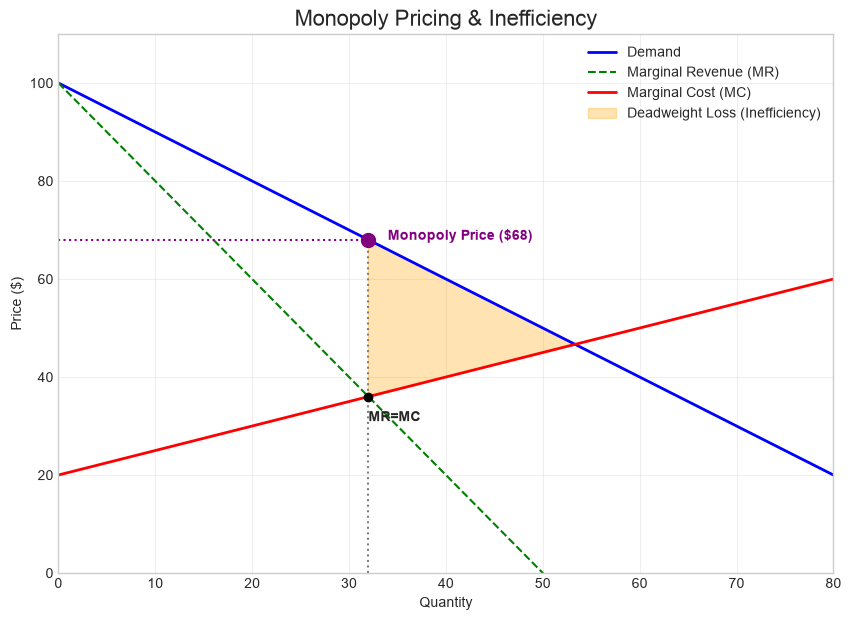

In [8]:
def plot_monopoly_optimization():
    # 1. Define Quantity Range
    Q = np.linspace(0, 100, 100)
    
    # 2. Define Curves
    # Demand: P = 100 - Q
    Demand = 100 - Q
    
    # Marginal Revenue: P = 100 - 2Q (Slope is twice as steep as Demand)
    MR = 100 - 2 * Q
    
    # Marginal Cost: P = 20 + 0.5Q (Rising supply cost)
    MC = 20 + 0.5 * Q
    
    # 3. Find Equilibrium (MR = MC)
    # 100 - 2Q = 20 + 0.5Q  =>  80 = 2.5Q  =>  Q = 32
    Q_monopoly = 32
    P_mc_at_Qm = 20 + 0.5 * Q_monopoly # Cost at Qm
    
    # 4. Find Monopoly Price (Go up to Demand curve)
    P_monopoly = 100 - Q_monopoly
    
    # 5. Plotting
    fig, ax = plt.subplots(figsize=(10, 7))
    
    ax.plot(Q, Demand, label='Demand', color='blue', linewidth=2)
    ax.plot(Q, MR, label='Marginal Revenue (MR)', color='green', linestyle='--')
    ax.plot(Q, MC, label='Marginal Cost (MC)', color='red', linewidth=2)
    
    # Draw Optimization Points
    # Point A: Where MR = MC (Quantity Decision)
    ax.scatter([Q_monopoly], [P_mc_at_Qm], color='black', zorder=5)
    ax.text(Q_monopoly, P_mc_at_Qm - 5, 'MR=MC', fontweight='bold')
    
    # Point B: Monopoly Price
    ax.scatter([Q_monopoly], [P_monopoly], color='purple', s=100, zorder=5)
    ax.text(Q_monopoly + 2, P_monopoly, f'Monopoly Price (${P_monopoly})', color='purple', fontweight='bold')
    
    # Visual Guides
    ax.vlines(Q_monopoly, 0, P_monopoly, linestyle=':', color='gray')
    ax.hlines(P_monopoly, 0, Q_monopoly, linestyle=':', color='purple')
    
    # === SHADING THE DEADWEIGHT LOSS ===
    # DWL is the triangle between Q_monopoly and Q_competitive (where MC = Demand)
    # Find Competitive Q: Demand = MC => 100 - Q = 20 + 0.5Q => 80 = 1.5Q => Q = 53.3
    Q_comp = 80 / 1.5
    P_comp = 100 - Q_comp
    
    # Fill Triangle
    dwl_x = [Q_monopoly, Q_comp, Q_monopoly]
    dwl_y = [P_monopoly, P_comp, P_mc_at_Qm]
    ax.fill(dwl_x, dwl_y, color='orange', alpha=0.3, label='Deadweight Loss (Inefficiency)')
    
    ax.set_title('Monopoly Pricing & Inefficiency', fontsize=16)
    ax.set_xlabel('Quantity')
    ax.set_ylabel('Price ($)')
    ax.set_xlim(0, 80)
    ax.set_ylim(0, 110)
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    plt.show()

plot_monopoly_optimization()

### **4. Case Study Animation: The Browser Wars**

Market structure changes over time. 
* **2008:** Microsoft Internet Explorer was a near-Monopoly.
* **2012:** Market became Competitive (Chrome, Firefox, IE fighting).
* **2023:** Chrome is now the dominant Oligopoly leader.

We will visualize this shift using synthetic data based on real history.

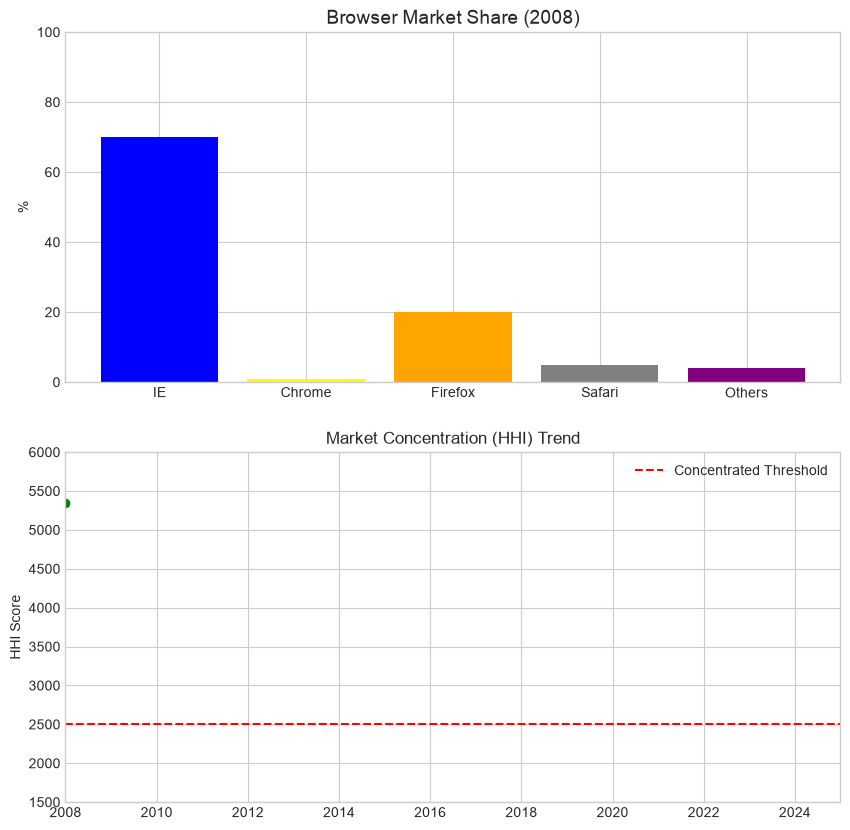

In [9]:
# === DATA GENERATION ===
years = np.arange(2008, 2025)
# Synthetic market shares approximation (IE, Chrome, Firefox, Safari, Others)
ie_share = [70, 60, 45, 30, 20, 15, 10, 5, 4, 3, 2, 2, 2, 1, 1, 1, 1]
chrome_share = [1, 5, 15, 30, 40, 45, 50, 55, 60, 63, 65, 64, 63, 64, 65, 66, 65]
firefox_share = [20, 25, 30, 25, 20, 18, 15, 12, 10, 8, 6, 5, 4, 3, 3, 3, 3]
safari_share = [5, 6, 7, 10, 12, 14, 15, 16, 17, 18, 19, 20, 21, 22, 21, 20, 21]
others_share = [4, 4, 3, 5, 8, 8, 10, 12, 9, 8, 8, 9, 10, 10, 10, 10, 10]

data = pd.DataFrame({
    'Year': years,
    'IE': ie_share,
    'Chrome': chrome_share,
    'Firefox': firefox_share,
    'Safari': safari_share,
    'Others': others_share
})

# Function to animate
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 10))

def animate_browsers(i):
    year = years[i]
    row = data.iloc[i]
    shares = [row['IE'], row['Chrome'], row['Firefox'], row['Safari'], row['Others']]
    labels = ['IE', 'Chrome', 'Firefox', 'Safari', 'Others']
    colors = ['blue', 'yellow', 'orange', 'gray', 'purple']
    
    # Calc HHI
    hhi = sum([s**2 for s in shares])
    
    # Ax1: Bar Chart
    ax1.clear()
    ax1.bar(labels, shares, color=colors)
    ax1.set_ylim(0, 100)
    ax1.set_title(f"Browser Market Share ({year})", fontsize=14)
    ax1.set_ylabel("%")
    
    # Ax2: HHI Line Chart Tracking
    ax2.clear()
    current_hhis = []
    for y_idx in range(i + 1):
        r = data.iloc[y_idx]
        s = [r['IE'], r['Chrome'], r['Firefox'], r['Safari'], r['Others']]
        current_hhis.append(sum([x**2 for x in s]))
        
    ax2.plot(years[:i+1], current_hhis, marker='o', color='green')
    ax2.set_xlim(2008, 2025)
    ax2.set_ylim(1500, 6000)
    ax2.axhline(2500, color='red', linestyle='--', label='Concentrated Threshold')
    ax2.set_title("Market Concentration (HHI) Trend")
    ax2.set_ylabel("HHI Score")
    ax2.legend()

anim = animation.FuncAnimation(fig, animate_browsers, frames=len(years), interval=500)
rc('animation', html='jshtml')
anim

---
## **5. Homework Assignment**

**Objective:** Apply HHI and Market Structure concepts to local contexts.

#### **Question 1: The Thai Telecom Merger**
In 2023, the Thai mobile market consolidated. Based on the following estimated market shares, calculate the HHI.

**Market Data:**
* **True-DTAC:** 51%
* **AIS:** 46%
* **NT (National Telecom):** 3%

1.  Write a Python calculation to find the HHI.
2.  Classify the market: Competitive, Moderately Concentrated, or Highly Concentrated.

#### **Question 2: Analysis of Daily Decision**
Think about your last trip to a supermarket vs. buying a new smartphone.
* **Rice:** Why are prices for standard Jasmine Rice roughly the same across different brands?
* **Smartphones:** Why can Apple charge 40,000 THB while Xiaomi charges 10,000 THB for a device that does similar things?
* **Task:** Relate your answer to **Market Structures** (Perfect Competition vs. Monopolistic Competition/Oligopoly) and **Product Differentiation**.

*(Write your answers in the Markdown cell below)*

In [ ]:
# === HOMEWORK SPACE: QUESTION 1 ===
# Calculate HHI for Thai Telecoms here

shares_telecom = [51, 46, 3]
HHI = 0
for i in shares_telecom:
    HHI += i*i

print(HHI)

#Q2
# Becasue the cost of switching to other brand is way cheaper or easier than smartphone.
# Apple operates within a  Oligopolistic market structure, and it invest an enormous amount of money into research and innovation.

4726
